# Potato Disease Classification using EfficientNetV2S

**CropGuard AI: AI-Powered Crop Disease Detection and Advisory System**

Final Year Project, The Islamia University of Bahawalpur (IUB)

| | |
|---|---|
| Students | Muhammad Ali Ejaz, Ahmad Siddique |
| Supervisor | Dr. Faheem Mushtaq |
| Notebook | Potato model (one of six crop models: wheat, rice, cotton, sugarcane, potato, corn) |

## Overview

This notebook trains the potato disease classifier used in CropGuard AI. The model takes a photo of a potato plant and predicts one of 6 classes: Bacteria, Early Blight, Fungi, Healthy, Late Blight and Virus.

- **Dataset:** images from two Kaggle datasets are combined: a field-based potato leaf disease dataset (photos taken in uncontrolled outdoor conditions) and the potato part of PlantVillage. The Pest and Nematode folders of the field dataset are not used, because they are not diseases (see section 2.1).
- **Model:** EfficientNetV2S pre-trained on ImageNet, with a small classification head on top.
- **Training:** four phases with progressive unfreezing. The base model is frozen first, then unfrozen and trained with smaller and smaller learning rates.
- **Evaluation:** accuracy, per-class precision/recall/F1, confusion matrix and sample predictions on the validation set.
- **Output:** the trained model and class files that are used by the CropGuard AI backend.

The notebook was run on Kaggle with a GPU.

**Before running:** the two Kaggle datasets from section 1.2 must be attached as input, and Internet must be turned on so that the pre-trained ImageNet weights can be downloaded.

## 1. Setup

### 1.1 Libraries

In [1]:
import os
import json
import shutil
import zipfile

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetV2S
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)
print("GPUs available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


### 1.2 Configuration

All paths and main settings are kept in one place so they are easy to change.

In [2]:
# Kaggle datasets that must be attached to the notebook
FIELD_INPUT = ("/kaggle/input/datasets/srkuhin/field-based-potato-leaf-disease-dataset/"
               "Potato Leaf Disease Dataset in Uncontrolled Environment")
PLANTVILLAGE_INPUT = "/kaggle/input/datasets/aarishasifkhan/plantvillage-potato-disease-dataset/PlantVillage"

# Working folders
MERGED_DIR = "/kaggle/working/potato_all"      # both sources, one folder per class
OUTPUT_DIR = "/kaggle/working"

# Data settings
IMG_SIZE = (384, 384)
BATCH_SIZE = 32
VALIDATION_SPLIT = 0.2
SEED = 42
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")

tf.keras.utils.set_random_seed(SEED)

## 2. Dataset Preparation

### 2.1 Combining the two sources

The two datasets use different class names, so every source folder is mapped to one final class name.

- The field dataset has the classes Bacteria, Fungi, Healthy, Nematode, Pest, Phytopthora and Virus.
- The PlantVillage potato folders are Early blight, Late blight and Healthy.
- The field folder `Phytopthora` (the spelling is wrong in the dataset) and the PlantVillage folder `Potato___Late_blight` are the same disease, late blight, which is caused by Phytophthora infestans. They are merged into one class, `Late_Blight`. Keeping them as two classes would split one disease into two outputs.

- The field folders `Pest` and `Nematode` are not used. Pest is insect damage and nematodes are tiny worms that live in the soil, so they are not leaf diseases, and this model only classifies diseases.

A prefix (`field` or `pv`) is added to every file name so that files never overwrite each other.

In [3]:
CLASS_MAP = {
    "Bacteria": "Bacteria",
    "Fungi": "Fungi",
    "Healthy": "Healthy",
    "Virus": "Virus",
    "Phytopthora": "Late_Blight",            # field dataset (misspelled folder name)
    "Potato___Early_blight": "Early_Blight",  # PlantVillage
    "Potato___Late_blight": "Late_Blight",    # PlantVillage
    "Potato___healthy": "Healthy",            # PlantVillage
}


# folders that are not diseases, so they are left out
SKIP_FOLDERS = ["Nematode", "Pest"]


def copy_dataset(src_root, prefix):
    copied = 0
    for folder in os.listdir(src_root):
        src_cls = os.path.join(src_root, folder)
        if not os.path.isdir(src_cls) or folder in SKIP_FOLDERS:
            continue
        canonical = CLASS_MAP.get(folder)
        if not canonical:
            print(f"Unknown class '{folder}' in {prefix}, skipping")
            continue
        dst_cls = os.path.join(MERGED_DIR, canonical)
        os.makedirs(dst_cls, exist_ok=True)
        for fname in os.listdir(src_cls):
            if not fname.lower().endswith(IMAGE_EXTENSIONS):
                continue
            dst = os.path.join(dst_cls, f"{prefix}_{fname}")
            if not os.path.exists(dst):
                shutil.copy2(os.path.join(src_cls, fname), dst)
                copied += 1
    return copied


os.makedirs(MERGED_DIR, exist_ok=True)
print("Field dataset:", copy_dataset(FIELD_INPUT, "field"), "images copied")
print("PlantVillage:", copy_dataset(PLANTVILLAGE_INPUT, "pv"), "images copied")

Field dataset: 2397 images copied
PlantVillage: 2152 images copied


### 2.2 Removing corrupt images

In [4]:
def remove_corrupt_images(root_dir):
    checked, removed = 0, 0
    for cls in os.listdir(root_dir):
        cls_dir = os.path.join(root_dir, cls)
        if not os.path.isdir(cls_dir):
            continue
        for fname in os.listdir(cls_dir):
            fpath = os.path.join(cls_dir, fname)
            checked += 1
            try:
                tf.image.decode_image(tf.io.read_file(fpath))
            except Exception:
                os.remove(fpath)
                removed += 1
    print(f"Checked {checked} images, removed {removed} corrupt files")


remove_corrupt_images(MERGED_DIR)

I0000 00:00:1793173954.363739      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793173954.367216      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Checked 4549 images, removed 0 corrupt files


### 2.3 Class distribution

The table and the chart show how many images each class has from each source.

class            field  plantvillage   total
Bacteria           569             0     569
Early_Blight         0          1000    1000
Fungi              748             0     748
Healthy            201           152     353
Late_Blight        347          1000    1347
Virus              532             0     532

Total: 4549 images in 6 classes


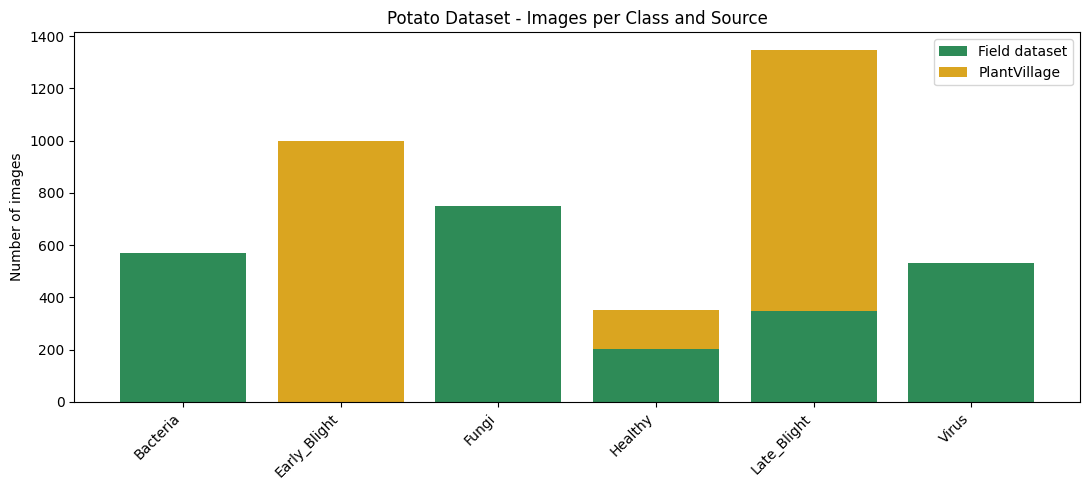

In [5]:
class_counts = {}
for cls in sorted(os.listdir(MERGED_DIR)):
    files = [f for f in os.listdir(os.path.join(MERGED_DIR, cls)) if f.lower().endswith(IMAGE_EXTENSIONS)]
    class_counts[cls] = {
        "field": len([f for f in files if f.startswith("field_")]),
        "plantvillage": len([f for f in files if f.startswith("pv_")]),
    }

print(f"{'class':14s} {'field':>7s} {'plantvillage':>13s} {'total':>7s}")
for cls, c in class_counts.items():
    print(f"{cls:14s} {c['field']:7d} {c['plantvillage']:13d} {c['field'] + c['plantvillage']:7d}")

total = sum(c["field"] + c["plantvillage"] for c in class_counts.values())
print(f"\nTotal: {total} images in {len(class_counts)} classes")

names = list(class_counts.keys())
field_n = [class_counts[c]["field"] for c in names]
pv_n = [class_counts[c]["plantvillage"] for c in names]

plt.figure(figsize=(11, 5))
plt.bar(names, field_n, label="Field dataset", color="seagreen")
plt.bar(names, pv_n, bottom=field_n, label="PlantVillage", color="goldenrod")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Number of images")
plt.title("Potato Dataset - Images per Class and Source")
plt.legend()
plt.tight_layout()
plt.show()

The classes are not balanced, so class weights are used during training (section 4). The chart also shows that Early Blight comes only from PlantVillage, while Bacteria, Fungi and Virus come only from the field dataset. Only Healthy and Late Blight have images from both sources.

## 3. Loading the Data

`image_dataset_from_directory` reads the images from the merged folder and splits them 80% for training and 20% for validation. The same seed is used for both calls so the two subsets do not overlap.

In [6]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    MERGED_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", validation_split=VALIDATION_SPLIT,
    subset="training", seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    MERGED_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", validation_split=VALIDATION_SPLIT,
    subset="validation", seed=SEED
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Classes:", class_names)
print("Number of classes:", NUM_CLASSES)

Found 4549 files belonging to 6 classes.
Using 3640 files for training.
Found 4549 files belonging to 6 classes.
Using 909 files for validation.
Classes: ['Bacteria', 'Early_Blight', 'Fungi', 'Healthy', 'Late_Blight', 'Virus']
Number of classes: 6


## 4. Class Weights

Because of the class imbalance, each class gets a weight that is higher for smaller classes. This makes mistakes on the smaller classes cost more during training.

In [7]:
def count_images(folder):
    return len([f for f in os.listdir(folder) if f.lower().endswith(IMAGE_EXTENSIONS)])


labels_flat = []
for i, cls in enumerate(class_names):
    labels_flat.extend([i] * count_images(os.path.join(MERGED_DIR, cls)))
labels_flat = np.array(labels_flat)

cw_values = compute_class_weight("balanced", classes=np.unique(labels_flat), y=labels_flat)
class_weight_dict = {i: w for i, w in enumerate(cw_values)}

for i, cls in enumerate(class_names):
    print(f"{cls}: {class_weight_dict[i]:.3f}")

Bacteria: 1.332
Early_Blight: 0.758
Fungi: 1.014
Healthy: 2.148
Late_Blight: 0.563
Virus: 1.425


## 5. Augmentation and Preprocessing

A light augmentation is applied to the training images only: random flips, small rotation and zoom, and small brightness and contrast changes. The validation images are only preprocessed, not augmented, so the validation score stays consistent.

In [8]:
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.1),
    layers.RandomContrast(0.1),
])


def prep_train(img, lbl):
    return preprocess_input(augmentation(img)), lbl


def prep_val(img, lbl):
    return preprocess_input(img), lbl


train_ds_p = train_ds.map(prep_train, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
val_ds_p = val_ds.map(prep_val, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

## 6. Model

EfficientNetV2S is used as the base model with ImageNet weights and without its original top layer. On top of it we add:

- Global average pooling to turn the feature maps into one vector
- Batch normalization
- Dropout (0.4) to reduce overfitting
- A dense softmax layer with one output per class

The base model starts frozen so that only the new head is trained in the first phase.

In [9]:
base = EfficientNetV2S(include_top=False, weights="imagenet", input_shape=(384, 384, 3))
base.trainable = False

inputs = keras.Input(shape=(384, 384, 3))
x = base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)

model.summary()

82420632/82420632 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 384, 384, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-s (Functional)   │ (None, 12, 12, 1280)   │    20,331,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,344,166 (77.61 MB)

 Trainable params: 10,246 (40.02 KB)

 Non-trainable params: 20,333,920 (77.57 MB)

### 6.1 Callbacks

- **EarlyStopping:** stops a phase when validation accuracy stops improving and goes back to the best weights.
- **ModelCheckpoint:** saves the model with the best validation accuracy to `potato_best.keras`.
- **ReduceLROnPlateau:** lowers the learning rate when validation loss stops improving.
- **BackupAndRestore:** saves training progress so a crashed session can continue.

The same list is used for phases 1 to 3. In phase 4 the early stopping callback is replaced by one with more patience.

In [10]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(f"{OUTPUT_DIR}/potato_best.keras", monitor="val_accuracy", save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7),
    keras.callbacks.BackupAndRestore(f"{OUTPUT_DIR}/potato_backup/")
]

## 7. Training

Training is done in four phases. The learning rate gets smaller in every phase, so the pre-trained weights are changed gently once the base model is unfrozen.

| Phase | Base model | Learning rate | Max epochs |
|---|---|---|---|
| 1 | Frozen | 1e-3 | 10 |
| 2 | Fully unfrozen | 1e-4 | 10 |
| 3 | Fully unfrozen | 5e-5 | 15 |
| 4 | Fully unfrozen (best weights reloaded) | 1e-5 | 15 |

### Phase 1: Frozen base

Only the new classification head is trained. This gives the head sensible weights before the base model is touched.

In [11]:
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy", metrics=["accuracy"])

h1 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=10,
               class_weight=class_weight_dict, callbacks=callbacks)

print(f"Phase 1 best validation accuracy: {max(h1.history['val_accuracy']) * 100:.2f}%")

Epoch 1/10


2026-10-28 07:53:38.548915: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 07:53:38.717601: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 07:53:39.843097: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 07:53:40.023428: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 07:53:41.650884: E external/local_xla/xla/stream_

113/114 ━━━━━━━━━━━━━━━━━━━━ 0s 515ms/step - accuracy: 0.5134 - loss: 1.4681

2026-10-28 07:55:09.431038: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 07:55:09.590354: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 07:55:10.661120: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 07:55:10.828946: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 07:55:12.442649: E external/local_xla/xla/stream_

114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 800ms/step - accuracy: 0.5146 - loss: 1.4645

2026-10-28 07:55:55.457322: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 07:55:55.605567: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 07:55:56.491993: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 07:55:56.641923: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 07:55:58.113836: E external/local_xla/xla/stream_

114/114 ━━━━━━━━━━━━━━━━━━━━ 188s 1s/step - accuracy: 0.6470 - loss: 1.0560 - val_accuracy: 0.8075 - val_loss: 0.7175 - learning_rate: 0.0010
Epoch 2/10
114/114 ━━━━━━━━━━━━━━━━━━━━ 73s 627ms/step - accuracy: 0.8113 - loss: 0.5952 - val_accuracy: 0.8427 - val_loss: 0.4486 - learning_rate: 0.0010
Epoch 3/10
114/114 ━━━━━━━━━━━━━━━━━━━━ 73s 628ms/step - accuracy: 0.8324 - loss: 0.5116 - val_accuracy: 0.8823 - val_loss: 0.3392 - learning_rate: 0.0010
Epoch 4/10
114/114 ━━━━━━━━━━━━━━━━━━━━ 71s 610ms/step - accuracy: 0.8349 - loss: 0.4870 - val_accuracy: 0.8735 - val_loss: 0.3524 - learning_rate: 0.0010
Epoch 5/10
114/114 ━━━━━━━━━━━━━━━━━━━━ 74s 630ms/step - accuracy: 0.8618 - loss: 0.4437 - val_accuracy: 0.8900 - val_loss: 0.3125 - learning_rate: 0.0010
Epoch 6/10
114/114 ━━━━━━━━━━━━━━━━━━━━ 85s 655ms/step - accuracy: 0.8607 - loss: 0.4191 - val_accuracy: 0.9043 - val_loss: 0.2973 - learning_rate: 0.0010
Epoch 7/10
114/114 ━━━━━━━━━━━━━━━━━━━━ 74s 634ms/step - accuracy: 0.8698 - loss: 0

### Phase 2: Full fine-tuning (lr = 1e-4)

The whole base model is unfrozen so the pre-trained features can adapt to potato leaves.

In [12]:
base.trainable = True

model.compile(optimizer=keras.optimizers.Adam(1e-4),
              loss="categorical_crossentropy", metrics=["accuracy"])

h2 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=10,
               class_weight=class_weight_dict, callbacks=callbacks)

print(f"Phase 2 best validation accuracy: {max(h2.history['val_accuracy']) * 100:.2f}%")

Epoch 1/10


2026-10-28 08:08:49.136954: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 08:08:49.324895: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 08:08:54.590818: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 08:08:54.770771: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 08:08:56.726082: E external/local_xla/xla/stream_

113/114 ━━━━━━━━━━━━━━━━━━━━ 0s 921ms/step - accuracy: 0.7676 - loss: 0.7886

2026-10-28 08:12:00.416214: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 08:12:00.588884: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 08:12:04.790883: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 08:12:04.968086: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-28 08:12:06.665052: E external/local_xla/xla/stream_

114/114 ━━━━━━━━━━━━━━━━━━━━ 377s 2s/step - accuracy: 0.8363 - loss: 0.5459 - val_accuracy: 0.8757 - val_loss: 0.4800 - learning_rate: 1.0000e-04
Epoch 2/10
114/114 ━━━━━━━━━━━━━━━━━━━━ 119s 1s/step - accuracy: 0.9266 - loss: 0.2326 - val_accuracy: 0.9263 - val_loss: 0.2593 - learning_rate: 1.0000e-04
Epoch 3/10
114/114 ━━━━━━━━━━━━━━━━━━━━ 117s 1s/step - accuracy: 0.9473 - loss: 0.1587 - val_accuracy: 0.9417 - val_loss: 0.2053 - learning_rate: 1.0000e-04
Epoch 4/10
114/114 ━━━━━━━━━━━━━━━━━━━━ 115s 992ms/step - accuracy: 0.9654 - loss: 0.1308 - val_accuracy: 0.9373 - val_loss: 0.2278 - learning_rate: 1.0000e-04
Epoch 5/10
114/114 ━━━━━━━━━━━━━━━━━━━━ 144s 1s/step - accuracy: 0.9695 - loss: 0.0901 - val_accuracy: 0.9450 - val_loss: 0.2202 - learning_rate: 1.0000e-04
Epoch 6/10
114/114 ━━━━━━━━━━━━━━━━━━━━ 119s 1s/step - accuracy: 0.9791 - loss: 0.0663 - val_accuracy: 0.9494 - val_loss: 0.2058 - learning_rate: 3.0000e-05
Epoch 7/10
114/114 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0

### Phase 3: Full fine-tuning (lr = 5e-5)

Training continues with a different learning rate for finer updates.

In [13]:
model.compile(optimizer=keras.optimizers.Adam(5e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])

h3 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=15,
               class_weight=class_weight_dict, callbacks=callbacks)

print(f"Phase 3 best validation accuracy: {max(h3.history['val_accuracy']) * 100:.2f}%")

Epoch 1/15
114/114 ━━━━━━━━━━━━━━━━━━━━ 347s 2s/step - accuracy: 0.9766 - loss: 0.0723 - val_accuracy: 0.9516 - val_loss: 0.2334 - learning_rate: 5.0000e-05
Epoch 2/15
114/114 ━━━━━━━━━━━━━━━━━━━━ 116s 995ms/step - accuracy: 0.9799 - loss: 0.0699 - val_accuracy: 0.9516 - val_loss: 0.2046 - learning_rate: 5.0000e-05
Epoch 3/15
114/114 ━━━━━━━━━━━━━━━━━━━━ 117s 1s/step - accuracy: 0.9843 - loss: 0.0470 - val_accuracy: 0.9527 - val_loss: 0.1977 - learning_rate: 1.5000e-05
Epoch 4/15
114/114 ━━━━━━━━━━━━━━━━━━━━ 115s 993ms/step - accuracy: 0.9874 - loss: 0.0361 - val_accuracy: 0.9527 - val_loss: 0.1926 - learning_rate: 1.5000e-05
Epoch 5/15
114/114 ━━━━━━━━━━━━━━━━━━━━ 115s 988ms/step - accuracy: 0.9843 - loss: 0.0451 - val_accuracy: 0.9505 - val_loss: 0.2083 - learning_rate: 1.5000e-05
Epoch 6/15
114/114 ━━━━━━━━━━━━━━━━━━━━ 115s 988ms/step - accuracy: 0.9871 - loss: 0.0420 - val_accuracy: 0.9505 - val_loss: 0.2088 - learning_rate: 1.5000e-05
Phase 3 best validation accuracy: 95.27%


### Phase 4: Final polish (lr = 1e-5)

The best weights saved so far are loaded again and trained with a very small learning rate and more patience (5 epochs), to squeeze out the last bit of accuracy.

In [14]:
model.load_weights(f"{OUTPUT_DIR}/potato_best.keras")

callbacks[0] = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True)

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])

h4 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=15,
               class_weight=class_weight_dict, callbacks=callbacks)

print(f"Phase 4 best validation accuracy: {max(h4.history['val_accuracy']) * 100:.2f}%")

Epoch 1/15
114/114 ━━━━━━━━━━━━━━━━━━━━ 348s 2s/step - accuracy: 0.9887 - loss: 0.0338 - val_accuracy: 0.9527 - val_loss: 0.1985 - learning_rate: 1.0000e-05
Epoch 2/15
114/114 ━━━━━━━━━━━━━━━━━━━━ 116s 1s/step - accuracy: 0.9871 - loss: 0.0389 - val_accuracy: 0.9527 - val_loss: 0.2044 - learning_rate: 1.0000e-05
Epoch 3/15
114/114 ━━━━━━━━━━━━━━━━━━━━ 143s 1s/step - accuracy: 0.9890 - loss: 0.0364 - val_accuracy: 0.9549 - val_loss: 0.2003 - learning_rate: 3.0000e-06
Epoch 4/15
114/114 ━━━━━━━━━━━━━━━━━━━━ 119s 1s/step - accuracy: 0.9893 - loss: 0.0264 - val_accuracy: 0.9560 - val_loss: 0.1936 - learning_rate: 3.0000e-06
Epoch 5/15
114/114 ━━━━━━━━━━━━━━━━━━━━ 115s 994ms/step - accuracy: 0.9893 - loss: 0.0342 - val_accuracy: 0.9549 - val_loss: 0.1964 - learning_rate: 9.0000e-07
Epoch 6/15
114/114 ━━━━━━━━━━━━━━━━━━━━ 115s 993ms/step - accuracy: 0.9898 - loss: 0.0275 - val_accuracy: 0.9549 - val_loss: 0.1980 - learning_rate: 9.0000e-07
Epoch 7/15
114/114 ━━━━━━━━━━━━━━━━━━━━ 115s 994ms/s

### 7.1 Training curves

The plots below join all four phases. The dashed vertical lines show where a new phase starts.

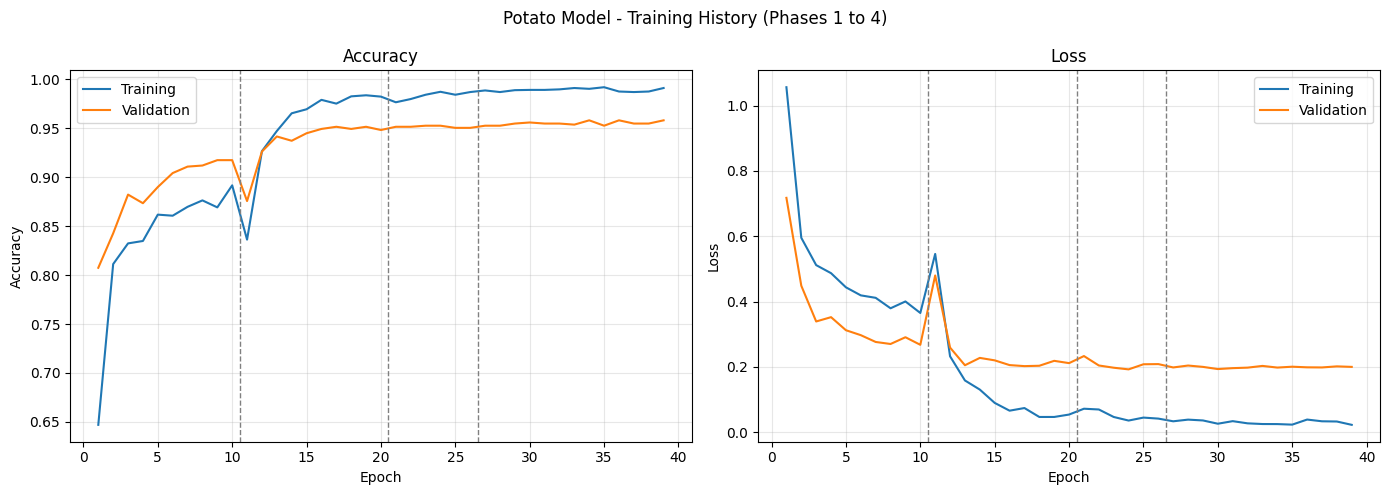

In [15]:
histories = [h1, h2, h3, h4]

train_acc, val_acc, train_loss, val_loss = [], [], [], []
phase_ends = []
for h in histories:
    train_acc += h.history["accuracy"]
    val_acc += h.history["val_accuracy"]
    train_loss += h.history["loss"]
    val_loss += h.history["val_loss"]
    phase_ends.append(len(train_acc))

epochs_range = range(1, len(train_acc) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, train_acc, label="Training")
axes[0].plot(epochs_range, val_acc, label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")

axes[1].plot(epochs_range, train_loss, label="Training")
axes[1].plot(epochs_range, val_loss, label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")

for ax in axes:
    for end in phase_ends[:-1]:
        ax.axvline(end + 0.5, color="gray", linestyle="--", linewidth=1)
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Potato Model - Training History (Phases 1 to 4)")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/potato_training_curves.png", dpi=150)
plt.show()

## 8. Evaluation

The model is evaluated on the validation set (20% of the images, never used for weight updates). Precision, recall and F1-score are reported for every class, followed by the confusion matrix.

In [16]:
y_true, y_pred = [], []
for imgs, lbls in val_ds_p:
    preds = model.predict(imgs, verbose=0)
    y_true.extend(np.argmax(lbls.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

val_accuracy = np.mean(y_true == y_pred)
print(f"Validation accuracy: {val_accuracy * 100:.2f}%  ({len(y_true)} images)\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

Validation accuracy: 95.82%  (909 images)

              precision    recall  f1-score   support

    Bacteria     0.9910    0.9649    0.9778       114
Early_Blight     1.0000    1.0000    1.0000       197
       Fungi     0.9048    0.8986    0.9017       148
     Healthy     0.8548    0.9636    0.9060        55
 Late_Blight     0.9760    0.9532    0.9645       299
       Virus     0.9300    0.9688    0.9490        96

    accuracy                         0.9582       909
   macro avg     0.9428    0.9582    0.9498       909
weighted avg     0.9593    0.9582    0.9584       909



The classification report shows how well each class is predicted. Classes with lower scores are usually the ones with symptoms that look similar to other classes, and the confusion matrix below shows which classes get mixed up.

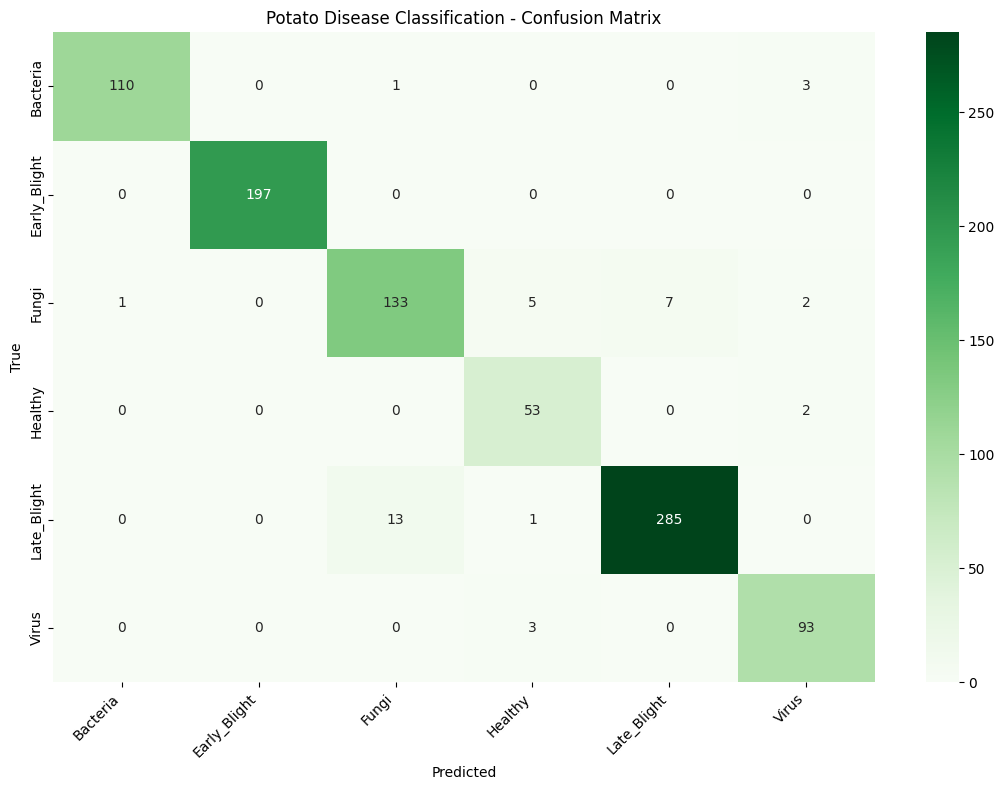

In [17]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(11, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Potato Disease Classification - Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/potato_confusion_matrix.png", dpi=150)
plt.show()

### 8.1 Sample predictions

A batch of validation images with the true label, the predicted label and the model's confidence. Green titles are correct predictions and red titles are mistakes.

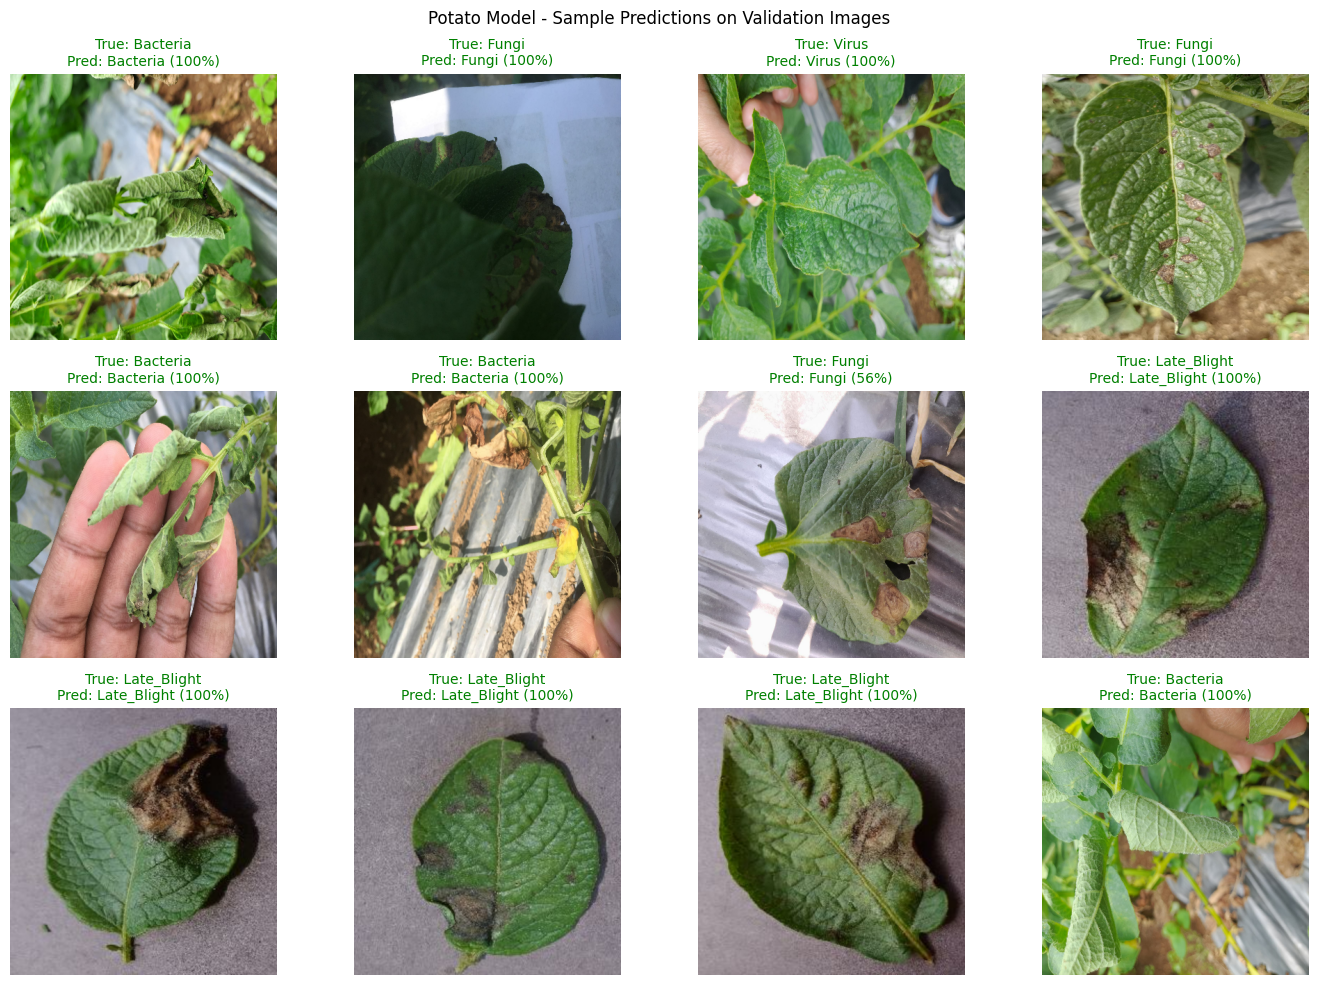

In [18]:
sample_images, sample_labels = next(iter(val_ds))
sample_probs = model.predict(preprocess_input(sample_images), verbose=0)

sample_true = np.argmax(sample_labels.numpy(), axis=1)
sample_pred = np.argmax(sample_probs, axis=1)

plt.figure(figsize=(14, 10))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(sample_images[i].numpy().astype("uint8"))
    plt.axis("off")

    confidence = sample_probs[i][sample_pred[i]] * 100
    correct = sample_true[i] == sample_pred[i]
    plt.title(f"True: {class_names[sample_true[i]]}\nPred: {class_names[sample_pred[i]]} ({confidence:.0f}%)",
              fontsize=10, color="green" if correct else "red")

plt.suptitle("Potato Model - Sample Predictions on Validation Images")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/potato_sample_predictions.png", dpi=150)
plt.show()

## 9. Saving the Model

The final model is saved together with JSON files that the CropGuard AI backend needs:

- `potato_class_names.json`: the class labels in the same order as the model outputs, in the form `potato__<disease>`
- `potato_class_map.json`: maps each label to the crop name and a readable disease name
- `potato_class_names_raw.json`: the original folder names

Everything is then packed into one zip file.

In [19]:
model.save(f"{OUTPUT_DIR}/potato_final.keras")
size_mb = os.path.getsize(f"{OUTPUT_DIR}/potato_final.keras") / 1024 / 1024
print(f"Model saved ({size_mb:.1f} MB)")

Model saved (233.7 MB)


In [20]:
DISEASE_NAMES = {
    "Bacteria": "Bacteria",
    "Early_Blight": "Early Blight",
    "Fungi": "Fungi",
    "Healthy": "Healthy",
    "Late_Blight": "Late Blight",
    "Virus": "Virus",
}

potato_class_map = {}
production_class_names = []

for cls in class_names:
    key = "potato__" + cls.lower()
    production_class_names.append(key)
    potato_class_map[key] = {"crop": "Potato", "disease": DISEASE_NAMES.get(cls, cls)}

with open(f"{OUTPUT_DIR}/potato_class_map.json", "w") as f:
    json.dump(potato_class_map, f, indent=2)
with open(f"{OUTPUT_DIR}/potato_class_names.json", "w") as f:
    json.dump(production_class_names, f, indent=2)
with open(f"{OUTPUT_DIR}/potato_class_names_raw.json", "w") as f:
    json.dump(class_names, f, indent=2)

print(json.dumps(potato_class_map, indent=2))

{
  "potato__bacteria": {
    "crop": "Potato",
    "disease": "Bacteria"
  },
  "potato__early_blight": {
    "crop": "Potato",
    "disease": "Early Blight"
  },
  "potato__fungi": {
    "crop": "Potato",
    "disease": "Fungi"
  },
  "potato__healthy": {
    "crop": "Potato",
    "disease": "Healthy"
  },
  "potato__late_blight": {
    "crop": "Potato",
    "disease": "Late Blight"
  },
  "potato__virus": {
    "crop": "Potato",
    "disease": "Virus"
  }
}


In [21]:
files = [
    f"{OUTPUT_DIR}/potato_final.keras",
    f"{OUTPUT_DIR}/potato_best.keras",
    f"{OUTPUT_DIR}/potato_class_map.json",
    f"{OUTPUT_DIR}/potato_class_names.json",
    f"{OUTPUT_DIR}/potato_confusion_matrix.png",
    f"{OUTPUT_DIR}/potato_training_curves.png",
    f"{OUTPUT_DIR}/potato_sample_predictions.png",
]

zip_path = f"{OUTPUT_DIR}/potato_model_package.zip"
with zipfile.ZipFile(zip_path, "w") as zf:
    for f in files:
        if os.path.exists(f):
            zf.write(f, arcname=os.path.basename(f))
            print(f"added {os.path.basename(f)} ({os.path.getsize(f) / 1024 / 1024:.1f} MB)")
        else:
            print(f"missing: {f}")

print(f"\nPackage: {zip_path} ({os.path.getsize(zip_path) / 1024 / 1024:.1f} MB)")

added potato_final.keras (233.7 MB)
added potato_best.keras (233.7 MB)
added potato_class_map.json (0.0 MB)
added potato_class_names.json (0.0 MB)
added potato_confusion_matrix.png (0.1 MB)
added potato_training_curves.png (0.1 MB)
added potato_sample_predictions.png (3.2 MB)

Package: /kaggle/working/potato_model_package.zip (470.7 MB)


## 10. Summary and Limitations

**Summary**

- Potato images from a field-based dataset and PlantVillage were combined and used to fine-tune an EfficientNetV2S model for 6 classes, using four training phases with decreasing learning rates.
- The two late blight folders (Phytopthora and PlantVillage Late blight) were merged into one class, because they are the same disease. The Pest and Nematode folders were left out, because they are not diseases.
- Class weights were used to handle the imbalance between classes, and a light augmentation was applied to the training images only.
- The final validation accuracy, per-class scores, confusion matrix and sample predictions are shown in section 8.
- The saved model and class files are used in the CropGuard AI website and mobile app.

**Limitations**

- The reported accuracy is validation accuracy. The same validation set was used for early stopping and for choosing the best checkpoint, and there is no separate test set, so the score can be slightly higher than what completely unseen images would give.
- Early Blight comes only from PlantVillage, and Bacteria, Fungi and Virus come only from the field dataset. The two sources look very different (PlantVillage has single leaves on a plain background, the field dataset has outdoor photos), so the model may partly learn the style of a source instead of only the disease. The Early Blight score is probably too optimistic, and a real field photo of early blight may be predicted as another class, for example Fungi.
- The sources were merged and split again randomly. PlantVillage is known to contain several photos of the same leaf, so very similar images can end up in both training and validation, which makes the accuracy look better than it really is.
- Bacteria, Fungi and Virus are broad groups from the field dataset, not names of single diseases.
- Pest damage and nematodes are not included, so a leaf with insect damage will be assigned to one of the disease classes or to Healthy.
- The classes were chosen to cover diseases only, so the results cannot be compared directly with a model trained with the Pest and Nematode classes.
- The images may be different from photos that farmers take with their phones in the field (lighting, background, camera quality), so accuracy in real use can be lower.

**Future work**

- Collect field photos of early blight so that this class is not only represented by lab-style images.
- Test the model on a separate set of potato images collected from fields in Pakistan.